No Excel file found. Creating mock dataset at: 'energy_data.xlsx'...
   ISO 50001 ENERGY REVIEW & BASELINE SUMMARY (EnB/EnPI)  
Monitoring Period      : 2023-10-01 to 2023-10-07
Total Energy Consumed  : 12,083.00 kWh
Overall Average Load   : 71.92 kW
Peak Demand (Lastspitze): 152.56 kW (at 2023-10-05 17:30:00)
Occupied Avg Load      : 126.33 kW
Unoccupied Baseload    : 48.87 kW (Grundlast)
Unoccupied Energy Share: 47.7% of total energy used when empty
----------------------------------------------------------
   ISO 50006 REGRESSION VALIDATION (EnPI Goodness-of-Fit) 
----------------------------------------------------------
Occupied Thermal Sensitivity  : -1.50 kW/°C (R² = 0.10)
Unoccupied Thermal Sensitivity: -0.51 kW/°C (R² = 0.40)
----------------------------------------------------------
   OPTIMIZATION POTENTIAL (15% Baseload Reduction)        
----------------------------------------------------------
Est. Annual Energy Saved: 45,101 kWh/year
Est. Annual Cost Saved  : €9,922.19 

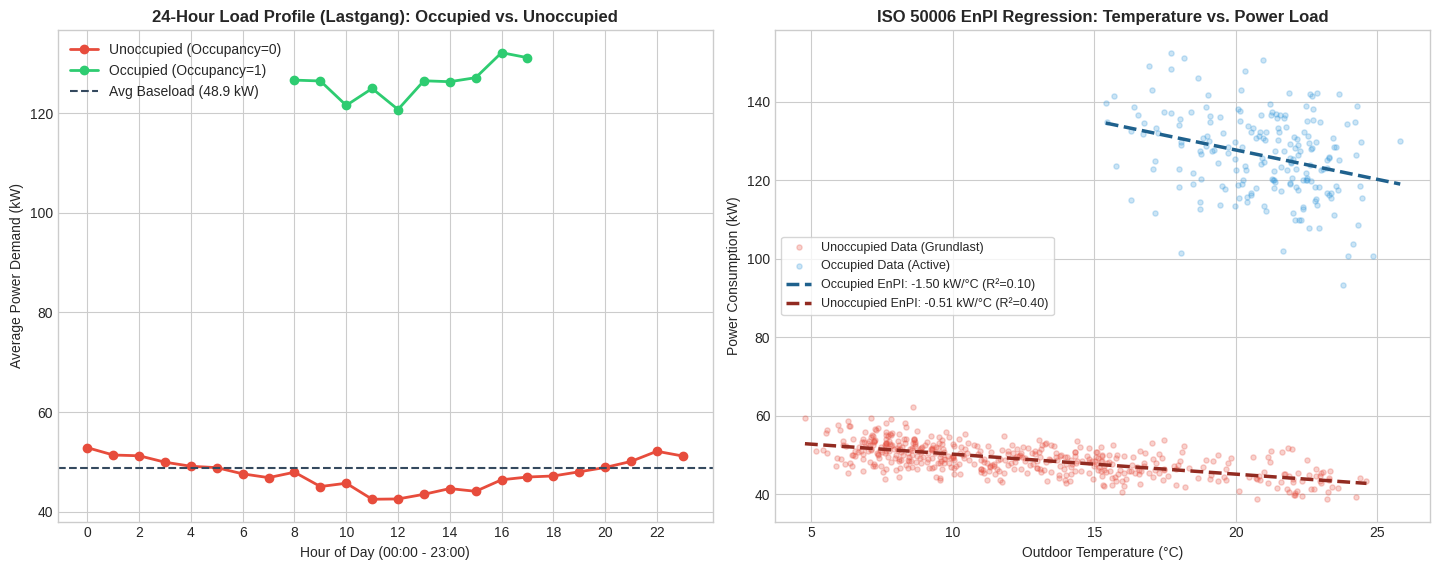

Saved updated high-resolution chart as: ISO_50001_Energy_Analysis_Charts.png


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Dynamic Excel file finder
excel_files = [f for f in os.listdir('.') if f.endswith(('.xlsx', '.xls'))]
if excel_files:
    file_path = excel_files[0]
    print(f"Found Excel file: '{file_path}'")
else:
    file_path = 'energy_data.xlsx'
    print(f"No Excel file found. Creating mock dataset at: '{file_path}'...")
    date_range = pd.date_range(start="2023-10-01 00:00:00", end="2023-10-07 23:45:00", freq="15min")
    np.random.seed(42)
    mock_data = []
    for dt in date_range:
        hour = dt.hour
        is_weekend = dt.dayofweek >= 5
        occupancy = 1 if (not is_weekend and 8 <= hour < 18) else 0
        temp = 15 + 8 * np.sin((hour - 6) / 24 * 2 * np.pi) + np.random.normal(0, 1)
        if occupancy == 1:
            power = 120 + (25 - temp) * 1.5 + np.random.normal(0, 10)
        else:
            power = 45 + (20 - temp) * 0.5 + np.random.normal(0, 3)
        mock_data.append({
            "date": dt,
            "Power Consumption": max(5.0, power),
            "Occupancy": occupancy,
            "Outdoor Temperature": temp
        })
    pd.DataFrame(mock_data).to_excel(file_path, index=False)

# 1. Load and clean dataset
df = pd.read_excel(file_path)
df.columns = df.columns.str.strip()
df["date"] = pd.to_datetime(df["date"])
df["Hour"] = df["date"].dt.hour
df["Energy_kWh"] = df["Power Consumption"] * 0.25

# ==========================================
# 2. ISO 50001 METRICS & STATISTICAL BASELINE
# ==========================================
total_kwh = df["Energy_kWh"].sum()
avg_power_kw = df["Power Consumption"].mean()
peak_power_kw = df["Power Consumption"].max()
peak_time = df.loc[df["Power Consumption"].idxmax(), "date"]

unoccupied_df = df[df["Occupancy"] == 0]
occupied_df = df[df["Occupancy"] == 1]

baseload_kw = unoccupied_df["Power Consumption"].mean()
occupied_avg_kw = occupied_df["Power Consumption"].mean()
unoccupied_kwh = unoccupied_df["Energy_kWh"].sum()
unoccupied_share_pct = (unoccupied_kwh / total_kwh) * 100

# Separate Linear Regressions + R-squared (ISO 50006 Goodness-of-Fit)
def calc_regression(subset):
    x = subset["Outdoor Temperature"].values
    y = subset["Power Consumption"].values
    slope, intercept = np.polyfit(x, y, 1)
    y_pred = slope * x + intercept
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    return slope, intercept, r2, x.min(), x.max()

occ_m, occ_b, occ_r2, occ_xmin, occ_xmax = calc_regression(occupied_df)
unocc_m, unocc_b, unocc_r2, unocc_xmin, unocc_xmax = calc_regression(unoccupied_df)

# Potential Savings Scenario (15% reduction in unoccupied baseload)
annual_factor = 365 / ((df["date"].max() - df["date"].min()).days + 1)
estimated_annual_savings_kwh = (unoccupied_kwh * 0.15) * annual_factor
estimated_eur_saved = estimated_annual_savings_kwh * 0.22
estimated_co2_saved_tons = (estimated_annual_savings_kwh * 0.38) / 1000

print("==========================================================")
print("   ISO 50001 ENERGY REVIEW & BASELINE SUMMARY (EnB/EnPI)  ")
print("==========================================================")
print(f"Monitoring Period      : {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Total Energy Consumed  : {total_kwh:,.2f} kWh")
print(f"Overall Average Load   : {avg_power_kw:.2f} kW")
print(f"Peak Demand (Lastspitze): {peak_power_kw:.2f} kW (at {peak_time})")
print(f"Occupied Avg Load      : {occupied_avg_kw:.2f} kW")
print(f"Unoccupied Baseload    : {baseload_kw:.2f} kW (Grundlast)")
print(f"Unoccupied Energy Share: {unoccupied_share_pct:.1f}% of total energy used when empty")
print("----------------------------------------------------------")
print("   ISO 50006 REGRESSION VALIDATION (EnPI Goodness-of-Fit) ")
print("----------------------------------------------------------")
print(f"Occupied Thermal Sensitivity  : {occ_m:+.2f} kW/°C (R² = {occ_r2:.2f})")
print(f"Unoccupied Thermal Sensitivity: {unocc_m:+.2f} kW/°C (R² = {unocc_r2:.2f})")
print("----------------------------------------------------------")
print("   OPTIMIZATION POTENTIAL (15% Baseload Reduction)        ")
print("----------------------------------------------------------")
print(f"Est. Annual Energy Saved: {estimated_annual_savings_kwh:,.0f} kWh/year")
print(f"Est. Annual Cost Saved  : €{estimated_eur_saved:,.2f} / year")
print(f"Est. CO2 Reduction      : {estimated_co2_saved_tons:.2f} tons CO2/year")
print("==========================================================\n")

# ==========================================
# 3. GENERATE UPDATED PORTFOLIO CHARTS
# ==========================================
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))

# Chart 1: Average 24-Hour Load Profile (Lastgang)
hourly_profile = df.groupby(["Hour", "Occupancy"])["Power Consumption"].mean().unstack()
hourly_profile.plot(ax=axes[0], marker="o", linewidth=2, color=["#e74c3c", "#2ecc71"])
axes[0].axhline(
    baseload_kw,
    color="#34495e",
    linestyle="--",
    linewidth=1.5,
)
axes[0].set_title(
    "24-Hour Load Profile (Lastgang): Occupied vs. Unoccupied",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Hour of Day (00:00 - 23:00)", fontsize=10)
axes[0].set_ylabel("Average Power Demand (kW)", fontsize=10)
axes[0].legend([
    "Unoccupied (Occupancy=0)",
    "Occupied (Occupancy=1)",
    f"Avg Baseload ({baseload_kw:.1f} kW)"
])
axes[0].set_xticks(range(0, 24, 2))

# Chart 2: Dual EnPI Regression (Occupied vs. Unoccupied)
axes[1].scatter(
    unoccupied_df["Outdoor Temperature"],
    unoccupied_df["Power Consumption"],
    alpha=0.25,
    s=14,
    color="#e74c3c",
    label="Unoccupied Data (Grundlast)"
)
axes[1].scatter(
    occupied_df["Outdoor Temperature"],
    occupied_df["Power Consumption"],
    alpha=0.25,
    s=14,
    color="#3498db",
    label="Occupied Data (Active)"
)

# Plot Occupied Trendline strictly within its actual temperature domain
x_occ_vals = np.linspace(occ_xmin, occ_xmax, 100)
axes[1].plot(
    x_occ_vals,
    occ_m * x_occ_vals + occ_b,
    color="#1f618d",
    linewidth=2.5,
    linestyle="--",
    label=f"Occupied EnPI: {occ_m:+.2f} kW/°C (R²={occ_r2:.2f})"
)

# Plot Unoccupied Trendline strictly within its actual temperature domain
x_unocc_vals = np.linspace(unocc_xmin, unocc_xmax, 100)
axes[1].plot(
    x_unocc_vals,
    unocc_m * x_unocc_vals + unocc_b,
    color="#922b21",
    linewidth=2.5,
    linestyle="--",
    label=f"Unoccupied EnPI: {unocc_m:+.2f} kW/°C (R²={unocc_r2:.2f})"
)

axes[1].set_title(
    "ISO 50006 EnPI Regression: Temperature vs. Power Load",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Outdoor Temperature (°C)", fontsize=10)
axes[1].set_ylabel("Power Consumption (kW)", fontsize=10)
axes[1].legend(loc="center left", fontsize=9, frameon=True)

plt.tight_layout()
plt.savefig("ISO_50001_Energy_Analysis_Charts.png", dpi=300)
plt.show()
print("Saved updated high-resolution chart as: ISO_50001_Energy_Analysis_Charts.png")